# QNN — Iris Dataset


## Librerias


In [1]:
#1.Import all libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import pennylane as qml
from torch.utils.data import DataLoader, TensorDataset
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


## Data


In [2]:
data = pd.DataFrame(datasets.load_iris().data, columns=datasets.load_iris().feature_names)
data['target'] = datasets.load_iris().target
data


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [3]:
data.target.unique()


array([0, 1, 2])

## Data Preparation


In [4]:
#2. Dataset preparation
torch.manual_seed(123)
np.random.seed(123)

n_qubits = 4
n_classes = 3

X = data.drop(columns='target').to_numpy()
y = data['target'].to_numpy()

X_train_raw, X_test_raw, y_train_np, y_test_np = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

# Normalize to [0, π] for Angle Embedding
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
y_test = torch.tensor(y_test_np, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")
print(f"Final shapes -> Train: {tuple(X_train.shape)}, Test: {tuple(X_test.shape)}")


Custom Dataset Loaded: Train=90, Test=60
Final shapes -> Train: (90, 4), Test: (60, 4)


## Quantum Neural Network


In [5]:
#3. QNN model definition
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    # Angle encoding: map 4 features to 4 qubits
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    # Entanglement layer
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

n_layers = 6
weight_shapes = {"weights": (n_layers, n_qubits)}

class QNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.post = nn.Linear(n_qubits, n_classes)

    def forward(self, x):
        x = self.qlayer(x)
        return self.post(x)


## Entrenamiento QNN


In [6]:
#5.Generic training function
def train_model(model, loader, epochs=30, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        for bx, by in loader:
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(loader)
        history.append(avg_loss)
        print(f"Epoch {epoch+1:2d} | Loss: {avg_loss:.4f}")
    return history


In [7]:
#6.Train QNN + timing
qnn_model = QNN()
start = time.time()
qnn_history = train_model(qnn_model, train_loader, epochs=30, lr=0.01)
qnn_time = time.time() - start
print(f"QNN training time: {qnn_time:.2f}s")


Epoch  1 | Loss: 1.2307
Epoch  2 | Loss: 1.1878
Epoch  3 | Loss: 1.1479
Epoch  4 | Loss: 1.1033
Epoch  5 | Loss: 1.0691
Epoch  6 | Loss: 1.0364
Epoch  7 | Loss: 0.9958
Epoch  8 | Loss: 0.9552
Epoch  9 | Loss: 0.9124
Epoch 10 | Loss: 0.8609
Epoch 11 | Loss: 0.8118
Epoch 12 | Loss: 0.7660
Epoch 13 | Loss: 0.7287
Epoch 14 | Loss: 0.6964
Epoch 15 | Loss: 0.6702
Epoch 16 | Loss: 0.6453
Epoch 17 | Loss: 0.6238
Epoch 18 | Loss: 0.6040
Epoch 19 | Loss: 0.5869
Epoch 20 | Loss: 0.5749
Epoch 21 | Loss: 0.5608
Epoch 22 | Loss: 0.5485
Epoch 23 | Loss: 0.5318
Epoch 24 | Loss: 0.5090
Epoch 25 | Loss: 0.5037
Epoch 26 | Loss: 0.4890
Epoch 27 | Loss: 0.4774
Epoch 28 | Loss: 0.4645
Epoch 29 | Loss: 0.4553
Epoch 30 | Loss: 0.4444
QNN training time: 1.07s


## Model Evaluation


In [8]:
#8.Evaluation function + print results
@torch.no_grad()
def evaluate(model, X_t, y_t, classes):
    model.eval()
    logits = model(X_t)
    preds = torch.argmax(logits, dim=1).numpy()
    probs = nn.functional.softmax(logits, dim=1).numpy()

    y_true = y_t.numpy()
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, average="macro", zero_division=0)
    rec = recall_score(y_true, preds, average="macro", zero_division=0)
    f1 = f1_score(y_true, preds, average="macro", zero_division=0)
    auc = roc_auc_score(label_binarize(y_true, classes=classes), probs, average="macro")
    return acc, prec, rec, f1, auc, probs, preds

classes = np.unique(y_train_np)
qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc, qnn_probs, qnn_preds = evaluate(
    qnn_model, X_test, y_test, classes
)
qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr, _, _ = evaluate(
    qnn_model, X_train, y_train, classes
)

print("\n=== Train vs Test ===")
print(
    f"QNN Train - Acc: {qnn_acc_tr:.4f} | Prec: {qnn_prec_tr:.4f} | Rec: {qnn_rec_tr:.4f} | "
    f"F1: {qnn_f1_tr:.4f} | AUC: {qnn_auc_tr:.4f}"
)
print(
    f"QNN Test  - Acc: {qnn_acc:.4f} | Prec: {qnn_prec:.4f} | Rec: {qnn_rec:.4f} | "
    f"F1: {qnn_f1:.4f} | AUC: {qnn_auc:.4f}"
)



=== Train vs Test ===
QNN Train - Acc: 0.9556 | Prec: 0.9556 | Rec: 0.9556 | F1: 0.9556 | AUC: 0.9906
QNN Test  - Acc: 0.9333 | Prec: 0.9360 | Rec: 0.9333 | F1: 0.9332 | AUC: 0.9746


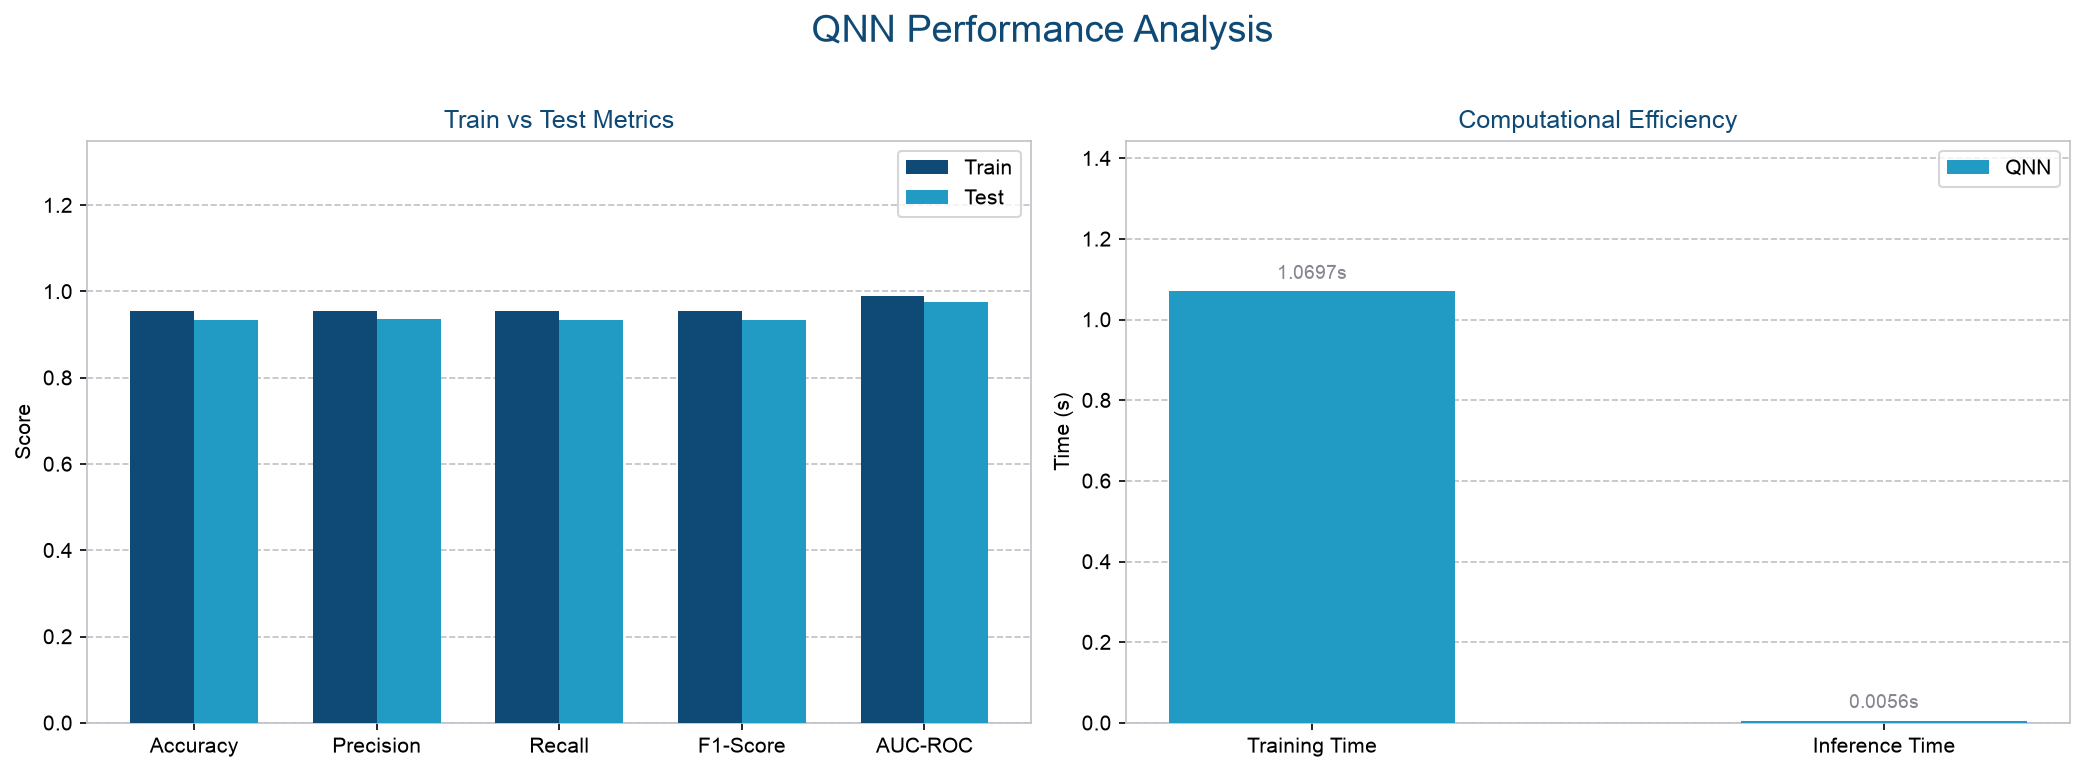

In [9]:
#9.Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    'font.sans-serif': ['Arial'],
    'axes.edgecolor': '#C0C0C8',
    'grid.color': '#C0C0C8',
    'grid.linestyle': '--'
})

@torch.no_grad()
def get_inference_time(model, data):
    start = time.time()
    _ = model(data)
    return time.time() - start

qnn_inf_time = get_inference_time(qnn_model, X_test)

train_color = '#0E4A75'
test_color = '#219BC3'
unir_gris = '#858591'

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle('QNN Performance Analysis', fontsize=18, y=1.02, color='#0E4A75')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
train_vals = [qnn_acc_tr, qnn_prec_tr, qnn_rec_tr, qnn_f1_tr, qnn_auc_tr]
test_vals = [qnn_acc, qnn_prec, qnn_rec, qnn_f1, qnn_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width/2, train_vals[i], width, color=train_color,
               label='Train' if i == 0 else '', zorder=3)
    axs[0].bar(x[i] + width/2, test_vals[i], width, color=test_color,
               label='Test' if i == 0 else '', zorder=3)

axs[0].set_ylabel('Score')
axs[0].set_title('Train vs Test Metrics', color='#0E4A75')
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc='upper right')
axs[0].grid(axis='y', zorder=0)

eff_labels = ['Training Time', 'Inference Time']
qnn_eff = [qnn_time, qnn_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, qnn_eff, 0.5, color=test_color, label='QNN', zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel('Time (s)')
axs[1].set_title('Computational Efficiency', color='#0E4A75')
max_time = max(qnn_eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc='upper right')
axs[1].grid(axis='y', zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], qnn_eff[i] + offset, f'{qnn_eff[i]:.4f}s',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [10]:
# Save metrics for IrisClassification comparison
import json
from pathlib import Path

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/Classification/IrisClassification/metrics."""
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        iris = base / "Notebooks" / "Classification" / "IrisClassification"
        if iris.is_dir():
            metrics_dir = iris / "metrics"
            metrics_dir.mkdir(parents=True, exist_ok=True)
            return metrics_dir
    metrics_dir = Path.cwd().resolve() / "Notebooks" / "Classification" / "IrisClassification" / "metrics"
    metrics_dir.mkdir(parents=True, exist_ok=True)
    return metrics_dir

metrics_dir = resolve_metrics_dir()

payload = {
    "model": "QNN",
    "family": "quantum",
    "protocol": {
        "dataset": "iris",
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
    },
    "train": {
        "accuracy": float(qnn_acc_tr),
        "precision": float(qnn_prec_tr),
        "recall": float(qnn_rec_tr),
        "f1": float(qnn_f1_tr),
        "auc": float(qnn_auc_tr),
    },
    "test": {
        "accuracy": float(qnn_acc),
        "precision": float(qnn_prec),
        "recall": float(qnn_rec),
        "f1": float(qnn_f1),
        "auc": float(qnn_auc),
    },
    "train_time_s": float(qnn_time),
    "inference_time_s": float(qnn_inf_time),
}

out = metrics_dir / "qnn_iris.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/ClassicalClassification/metrics/qnn_iris.json


## Storytelling plots

`figures/`: PCA sin frontera + con frontera del **mismo** modelo ya entrenado.
Puntos test usan `*_preds` del notebook; la malla usa `modelo.predict` (sin reentrenar).


In [ ]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

from storytelling import resolve_figures_dir, plot_iris_pca_story

figures_dir = resolve_figures_dir("Classification", "IrisClassification")
def _predict_fn(X):
    import torch
    qnn_model.eval()
    xt = torch.as_tensor(np.asarray(X, dtype=np.float32))
    with torch.no_grad():
        return torch.argmax(qnn_model(xt), dim=1).cpu().numpy()
predict_fn = _predict_fn
# y_pred_test = predicciones YA calculadas; predict_fn = modelo YA entrenado (solo malla)
plot_iris_pca_story(
    X_train, y_train, X_test, y_test,
    y_pred_test=qnn_preds,
    predict_fn=predict_fn,
    figures_dir=figures_dir,
    stem="qnn",
    title_model="QNN",
)
